In [1]:
'''
matching the stars from the beginning-rwe images
'''

'\nmatching the stars from the beginning-rwe images\n'

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import os
import review_findings_functions as rff
from tqdm.auto import tqdm

In [4]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [5]:
path = '/lustre/lrspec/ZTF_data/2022/1020/'

In [ ]:
#visually inspecting the coordinate offset for the brightest stars
#from gaia vs the brightest stars on the page
#in ds9

'''
looking at _640_zg_c06, ccd 3:
setting radius to 29 arcmin and max rows to 500000

here's our stars: 
point(1801.1026,2247.7228) # point=circle
point(744.91957,1910.9508) # point=circle
point(348.43471,805.60133) # point=circle
point(1538.0743,1378.7074) # point=circle
point(707.0757,2946.774) # point=circle
point(265.5332,2649.6537) # point=circle
point(920.09307,2578.9413) # point=circle
didn't find this one: point(406.78954,2672.4502) # point=circle

and here's where they appear to be:


box(1962.6613,2261.186,119.67305,59.836527,0)
box(907.97411,1906.4632,119.67305,59.836527,0)
box(514.48095,814.57698,119.67305,59.836527,0)
box(1701.1288,1392.1708,119.67305,59.836527,0)
box(864.1465,2942.2863,119.67305,59.836527,0)
box(422.60411,2660.1249,119.67305,59.836527,0)
box(1078.6597,2593.9006,119.67305,59.836527,0)

'''

In [ ]:
#this i did locally on my computer, but copying here
'''
import re

# Load the DS9 region file
region_file = "/content/640_zg_c06_x_1.reg"  # Update with your filename

extra_points_to_delete = 2 #update this too

input_fits = "/content/ztf_20221020163819_000640_zg_c06_x.fz_1.fits"

#below this should stay the same for all of then
# Lists to store parsed data
points = []
boxes = []

# Read and parse the file
with open(region_file, "r") as file:
    for line in file:
        line = line.strip()
        # Match point(x, y)
        match_point = re.match(r"point\(([\d.]+),([\d.]+)\)", line)
        if match_point:
            x, y = map(float, match_point.groups())
            points.append((x, y))
        
        # Match box(x, y, width, height, angle)
        match_box = re.match(r"box\(([\d.]+),([\d.]+),([\d.]+),([\d.]+),([\d.]+)\)", line)
        if match_box:
            x, y, width, height, angle = map(float, match_box.groups())
            boxes.append((x, y, width, height, angle))

# Print results
print("Points:", points)
print("Boxes:", boxes)

#had an extra point so
points=points[:-extra_points_to_delete]


# Compute offsets
offsets = []
for (px, py), (bx, by, _, _, _) in zip(points, boxes):
    delta_x = px - bx
    delta_y = py - by
    offsets.append((delta_x, delta_y))

# Convert to NumPy array for easy manipulation
offsets = np.array(offsets)

# Print results
print("Pixel Offsets (Δx, Δy):")
print(offsets)

# Compute mean offsets
mean_offset_x = np.mean(offsets[:, 0])
mean_offset_y = np.mean(offsets[:, 1])

stdv_offset_x = np.std(offsets[:, 0])
stdv_offset_y = np.std(offsets[:, 1])

print(f"\nMean Offset: Δx = {mean_offset_x:.4f}, Δy = {mean_offset_y:.4f}")
print(f"\nStdv of Offsets: Δx = {stdv_offset_x:.4f}, Δy = {stdv_offset_y:.4f}")

# Load the FITS file
output_fits = input_fits+"_adjusted.fits"  # New file name

with fits.open(input_fits) as hdul:
    for i in range(1, 2):  # this generally only works for one
      hdr = hdul[i].header  # Get the header
      wcs = WCS(hdr)  # Load WCS

      # Offset values (in pixels)
      delta_x, delta_y = mean_offset_x, mean_offset_y  # Example: move 5 pixels right, 3 pixels down

      # Adjust the reference pixel
      wcs.wcs.crpix[0] -= delta_x  # X-axis
      wcs.wcs.crpix[1] -= delta_y  # Y-axis

      # Update the header with the new WCS
      new_header = wcs.to_header()
      hdr.update(new_header)

    # Save to a new FITS file
    hdul.writeto(output_fits, overwrite=True)
    
'''

In [ ]:
#now trying to do it without the manual Ds9 component

In [3]:
input_fits = "ztf_20221020163819_000640_zg_c06_x.fits.fz"

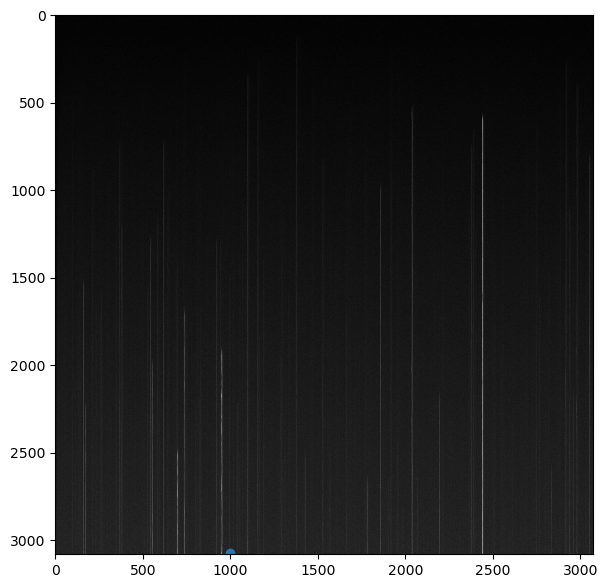

In [9]:
hdul_start = fits.open(path+input_fits)
array = hdul_start[1].data
plt.imshow(np.sqrt(hdul_start[1].data))
plt.scatter(1000,3075)

In [9]:
np.shape(hdul_start[1].data)

(3080, 3072)

In [10]:
hdul_start[1].data[3075]

array([119.35956, 126.06426, 127.82652, ..., 174.07013, 174.27948,
       169.66862], dtype=float32)

In [25]:

means = np.zeros((np.shape(array)[1], np.shape(array)[0]-30))# 
for x_coord in tqdm(range(np.shape(array)[1])):
    for i in range(np.shape(array)[0]-30):
        means[x_coord, i]  = np.mean(array[i:i+30,x_coord])

  0%|          | 0/3072 [00:00<?, ?it/s]

In [34]:
# plt.imshow(means)

diffs = np.zeros((np.shape(array)[1], np.shape(array)[0]-70))
for x_coord in tqdm(range(np.shape(array)[1])):
    for i in range(np.shape(array)[0]-80):
        mean_1 = np.mean(array[i:i+30,x_coord])
        mean_2 = np.mean(array[i+50:i+80,x_coord])
        diff = mean_2-mean_1
        diffs[x_coord, i] = diff

  0%|          | 0/3072 [00:00<?, ?it/s]

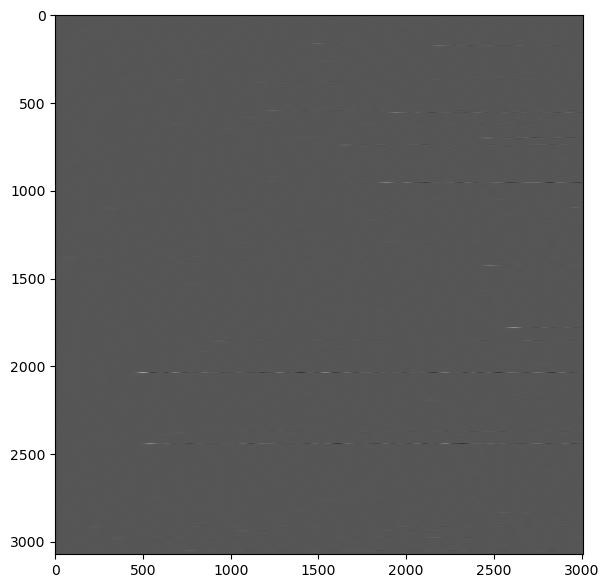

In [35]:
plt.imshow(diffs)

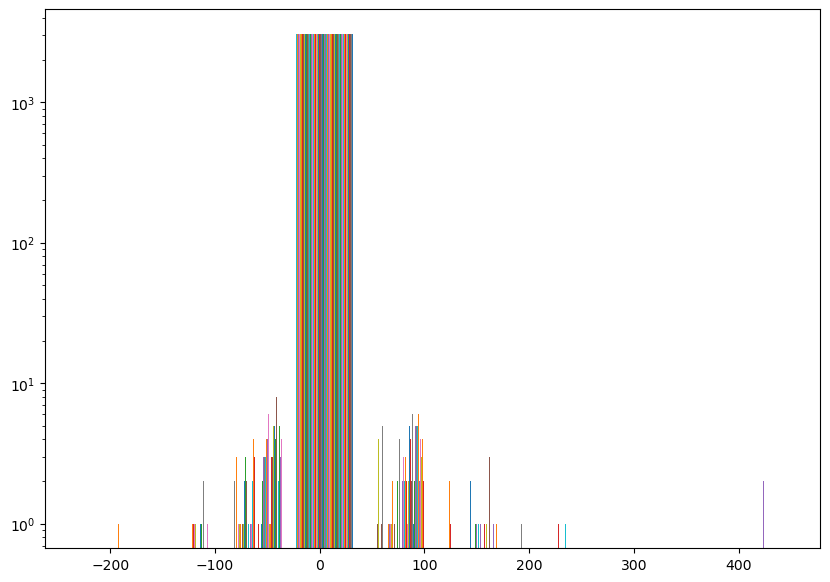

In [33]:
plt.hist(diffs)
plt.yscale('log')

In [45]:
diffs = []
for x_coord in tqdm(range(np.shape(array)[1])):
    for i in range(np.shape(array)[0]-80):
        mean_1 = np.mean(array[i:i+30,x_coord])
        mean_2 = np.mean(array[i+50:i+80,x_coord])
        diff = mean_2-mean_1
        if diff>100:
            last_x_coord = diffs[-1][0]
            last_y_coord = diffs[-1][1]
            last_diff = diffs[-1][2]
            if np.abs(x_coord-last_x_coord) < 3:
                if np.abs((i+50)-last_y_coord) > 20:
                    diffs.append(np.array((x_coord,i+50, diff)))
                else:
                    
            diffs.append(np.array((x_coord,i+50, diff)))
        continue

  0%|          | 0/3072 [00:00<?, ?it/s]

In [32]:
diffs = []
for x_coord in tqdm(range(np.shape(array)[1])):
    for i in range(np.shape(array)[0]-220):
        mean_1 = np.mean(array[i:i+100,x_coord])
        mean_2 = np.mean(array[i+120:i+220,x_coord])
        diff = mean_2-mean_1
        if diff>100:
            if len(diffs)>0:
                last_x_coord = diffs[-1][0]
                last_y_coord = diffs[-1][1]
                last_diff = diffs[-1][2]
                if np.abs(x_coord-last_x_coord) < 8:
                    if np.abs((i+40)-last_y_coord) > 100 and diff>300: #new star starting partway
                        diffs.append(np.array((x_coord,i+100, diff)))
                    else:
                        if last_diff < diff:
                            diffs[-1]=np.array((x_coord,i+100, diff)) #replace if this is just a brighter version of the last one
                        else: #if the last one was brighter and they're the same, just ignore this one
                            continue
                else:
                    diffs.append(np.array((x_coord,i+100, diff)))
            else:
                diffs.append(np.array((x_coord,i+100, diff)))
        continue

  0%|          | 0/3072 [00:00<?, ?it/s]

In [19]:
np.array(diffs)[:,2]

array([143.28507996, 117.57197571, 106.76306152, 151.70062256,
       248.27198792, 192.72181702, 160.34559631, 140.74565125,
       101.09669495, 117.16137695, 152.62249756, 114.20205688,
       105.79808044, 519.5279541 , 391.53353882, 163.69454956,
       195.72012329, 126.57049561, 168.05462646, 106.01098633,
       100.10073853, 578.72442627, 476.54611206, 314.85629272,
       142.68457031, 278.3248291 , 253.71388245, 208.25100708,
       169.79901123, 133.82141113, 100.1489563 , 205.28305054,
       166.83355713, 133.74543762, 123.37484741, 102.72000122,
       103.15078735, 137.49855042, 197.84619141, 159.48953247,
       133.22898865, 118.68359375, 197.29975891, 147.75665283,
       194.60516357, 167.07095337, 106.92120361, 117.11325073,
       110.20878601, 127.86767578, 132.309021  , 241.40087891,
       195.85620117, 106.27349854, 166.40815735, 137.14764404])

In [57]:
np.array(diffs)[3]

array([ 553, 1980])

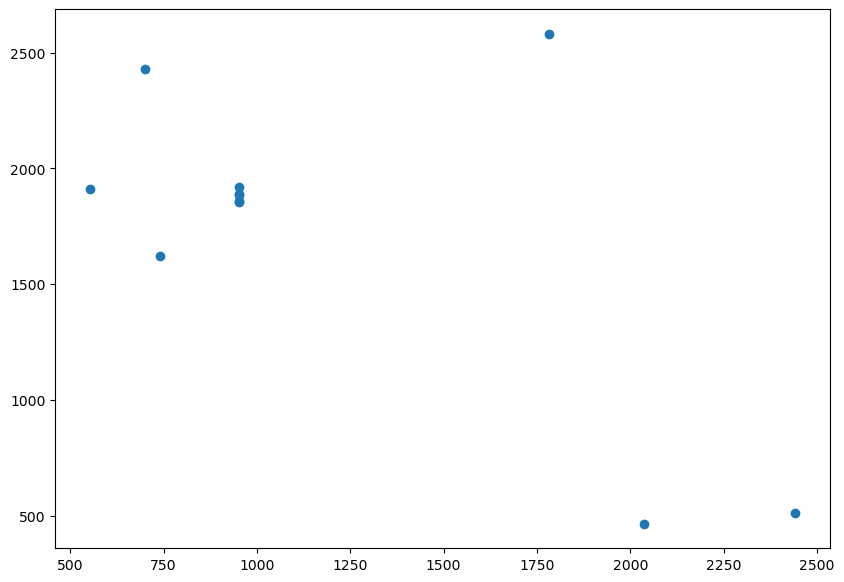

In [22]:
plt.scatter(np.array(diffs)[:,0], np.array(diffs)[:,1])

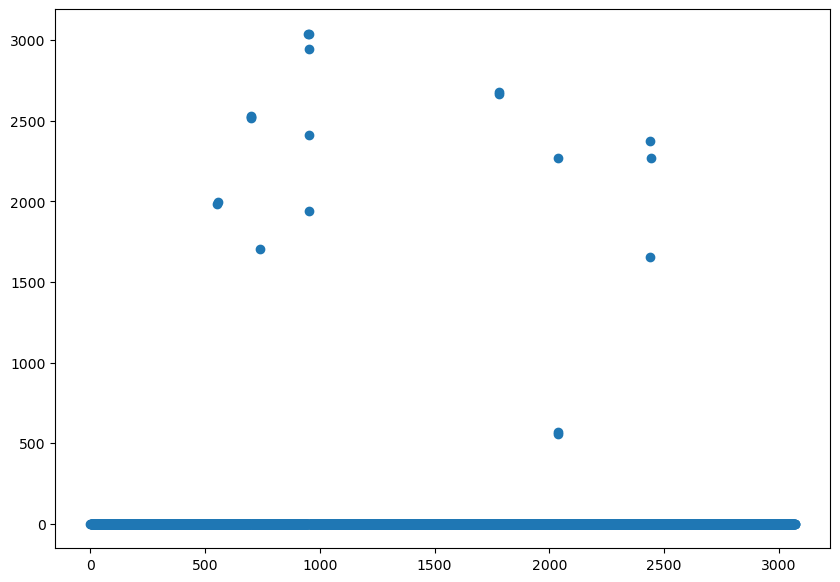

In [42]:
plt.scatter(range(np.shape(diffs)[0]),diffs)

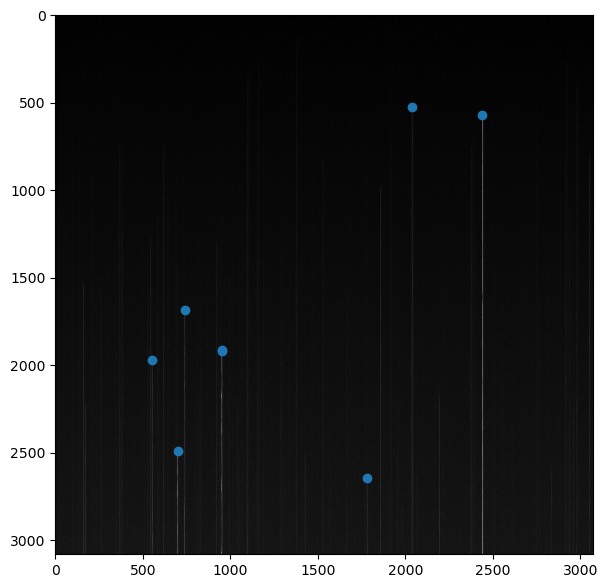

In [34]:
plt.imshow(array)
plt.scatter(np.array(diffs)[:,0], np.array(diffs)[:,1])

(1800.0, 2000.0)

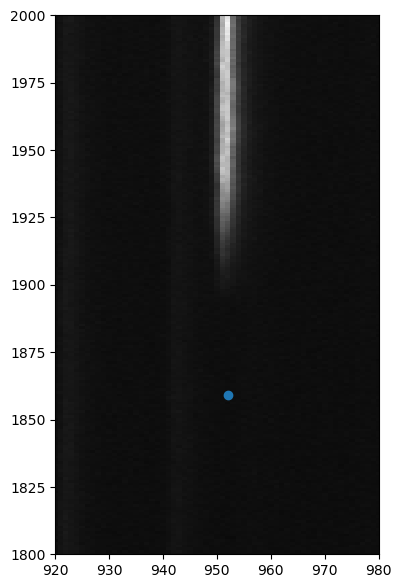

In [31]:
plt.imshow(array, aspect='.5')
plt.scatter(np.array(diffs)[:,0], np.array(diffs)[:,1])
plt.xlim(920,980)
plt.ylim(1800,2000)


In [36]:
import subprocess

In [37]:
def write_xylist(star_catalog, output_file):
    """
    Writes an XY list file from a given star catalog.
    
    Parameters:
    star_catalog (array-like): Nx2 or Nx3 array with columns (x, y, [magnitude]).
    output_file (str): Path to save the XY list file.
    """
    np.savetxt(output_file, star_catalog, fmt="%.6f")
    print(f"XY list saved to {output_file}")

In [42]:
def run_solve_field(xy_file, image_width, image_height, scale_low, scale_high, output_dir="."):
    """
    Runs Astrometry.net's solve-field with an XY list file.
    
    Parameters:
    xy_file (str): Path to the XY list file.
    image_width (int): Width of the original image.
    image_height (int): Height of the original image.
    scale_low (float): Lower bound of scale in arcsec/pixel.
    scale_high (float): Upper bound of scale in arcsec/pixel.
    output_dir (str): Directory to store output files.
    """
    cmd = [
        "solve-field", xy_file,
        "--x-column", "1", "--y-column", "2",
        "--width", str(image_width), "--height", str(image_height),
        "--scale-units", "arcsecperpix",
        "--scale-low", str(scale_low), "--scale-high", str(scale_high),
        "--dir", output_dir,
        "--overwrite"
    ]
    
    print("Running solve-field...")
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout)
    print(result.stderr)

array([[ 554., 1972.],
       [ 700., 2487.],
       [ 740., 1682.],
       [ 951., 1914.],
       [ 952., 1919.],
       [1781., 2641.],
       [2037.,  525.],
       [2441.,  570.]])

In [46]:
 # Example star catalog: (x, y) coordinates (can add magnitude if needed)
star_catalog = np.array(diffs)[:, :2]

xy_file = "stars.xy"
write_xylist(star_catalog, xy_file)

# Set parameters
image_width, image_height = np.shape(array)[1],np.shape(array)[0]  # Adjust to match your original image size
scale_low, scale_high = 1.2,1.2  # Adjust based on your expected scale (arcsec/pixel)

run_solve_field(xy_file, image_width, image_height, scale_low, scale_high)

XY list saved to stars.xy
Running solve-field...


FileNotFoundError: [Errno 2] No such file or directory: 'solve-field'